<a href="https://colab.research.google.com/github/oojobe/FB-/blob/main/COURSE_8_TEST_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import requests
import io
import pandas as pd

# URL of the CSV file
URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/d51iMGfp_t0QpO30Lym-dw/automobile-sales.csv"

# Fetch the data from the URL
response = requests.get(URL)

# Raise an error if the request failed
response.raise_for_status()

# Convert the response content into a readable format for pandas
csv_content = io.StringIO(response.text)

# Read the CSV data into a pandas dataframe
df = pd.read_csv(csv_content)

# Print confirmation
print('Data downloaded and read into a dataframe!')

# Optional: Show the first few rows of the dataframe
print(df.head())

Data downloaded and read into a dataframe!
         Date  Year Month  Recession  Consumer_Confidence  Seasonality_Weight  \
0  1980-01-31  1980   Jan          1               108.24                0.45   
1  1980-01-31  1980   Jan          1               108.24                0.45   
2  1980-01-31  1980   Jan          1               108.24                0.36   
3  1980-01-31  1980   Jan          1               108.24                0.38   
4  1980-02-29  1980   Feb          1                98.75                0.46   

   Price  Advertising_Expenditure  Competition    GDP  Growth_Rate  \
0  27704                   1417.5            7  60.22         0.01   
1  77270                    763.7            7  60.22         0.01   
2  19665                   1417.5            7  60.22         0.01   
3  36986                   1417.5            7  60.22         0.01   
4  26609                   2773.4            4  45.99        -0.31   

   unemployment_rate  Automobile_Sales     Vehicl

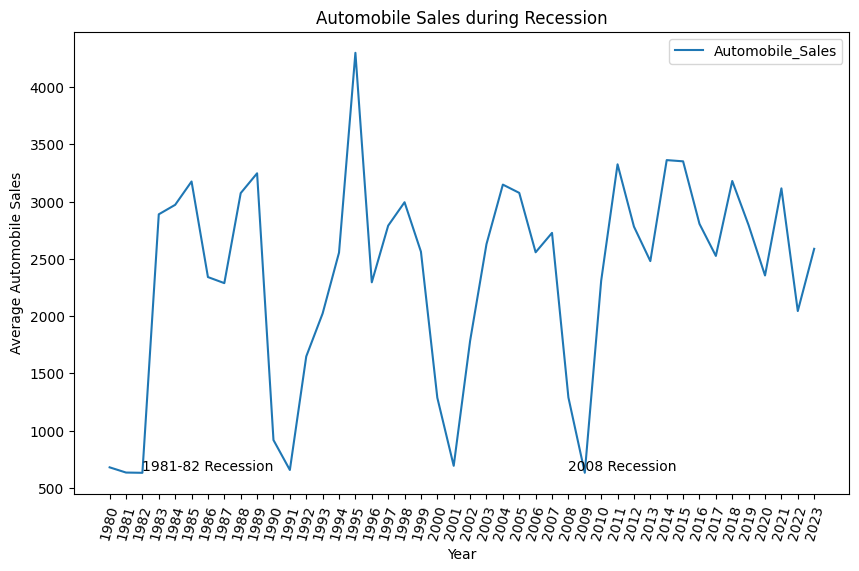

In [ ]:
plt.figure(figsize=(10, 6))
df_line = df.groupby('Year')['Automobile_Sales'].mean()
df_line.plot(kind = 'line')
plt.xticks(list(range(1980,2024)), rotation = 75)
plt.xlabel('Year')
plt.ylabel('Average Automobile Sales')
plt.title('Automobile Sales during Recession')
plt.text(1982, 650, '1981-82 Recession')
plt.text(2008, 650, '2008 Recession')
plt.legend()
plt.show()

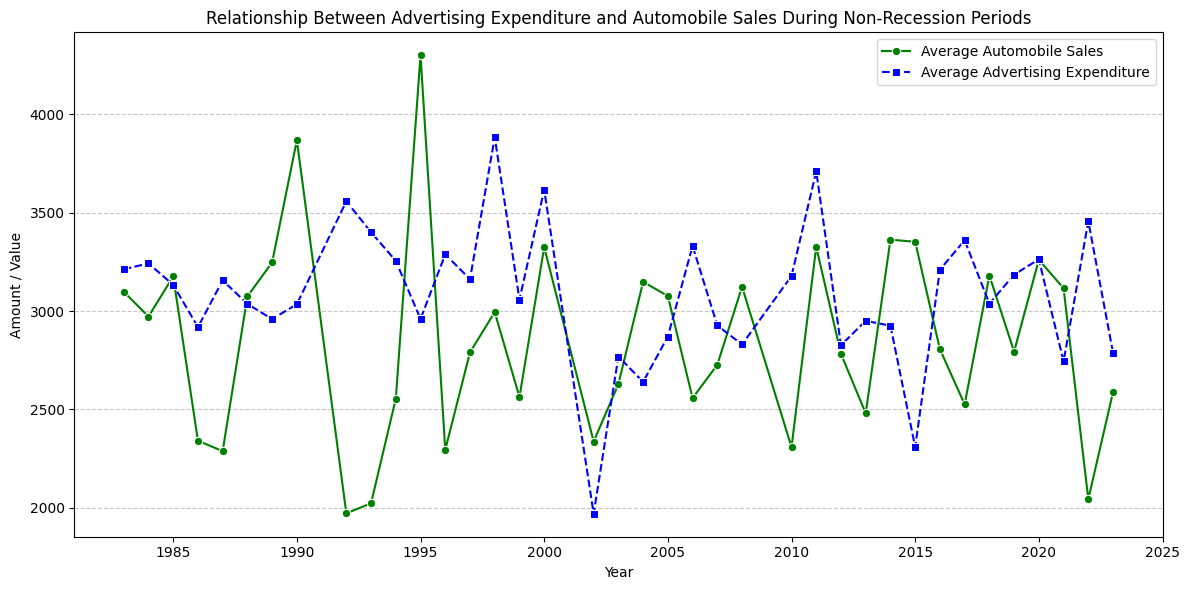

In [ ]:
# Assuming 'df' is your dataset
df_non_rec = df[df['Recession'] == 0]

# Calculate average automobile sales and average advertising expenditure by year (non-recession)
df_trends = df_non_rec.groupby('Year', as_index=False).agg(
    Avg_Sales=('Automobile_Sales', 'mean'),
    Avg_Ad_Spend=('Advertising_Expenditure', 'mean')
)

# Create line plots for average sales and advertising expenditure over the years
plt.figure(figsize=(12, 6))
sns.lineplot(data=df_trends, x='Year', y='Avg_Sales', marker='o', linestyle='-', color='green', label='Average Automobile Sales')
sns.lineplot(data=df_trends, x='Year', y='Avg_Ad_Spend', marker='s', linestyle='--', color='blue', label='Average Advertising Expenditure')

# Add labels, legend, title, and grid
plt.xlabel('Year')
plt.ylabel('Amount / Value')
plt.title('Relationship Between Advertising Expenditure and Automobile Sales During Non-Recession Periods')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Show the plot
plt.tight_layout()
plt.show()

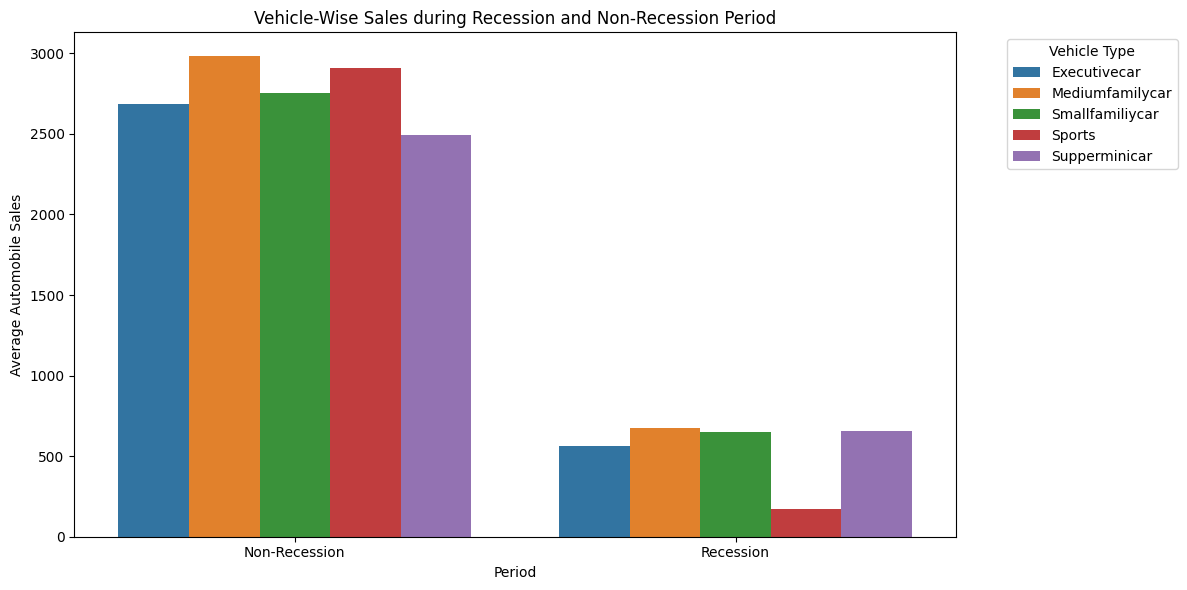

In [ ]:
# Group data by Recession and Vehicle_Type to compare sales
grouped_df = df.groupby(['Recession', 'Vehicle_Type'], as_index=False)['Automobile_Sales'].mean()

# Create the grouped bar chart using seaborn
plt.figure(figsize=(12, 6))
sns.barplot(x='Recession', y='Automobile_Sales', hue='Vehicle_Type', data=grouped_df)
plt.xticks(ticks=[0, 1], labels=['Non-Recession', 'Recession'])
plt.xlabel('Period')
plt.ylabel('Average Automobile Sales')
plt.title('Vehicle-Wise Sales during Recession and Non-Recession Period')
plt.legend(title='Vehicle Type', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

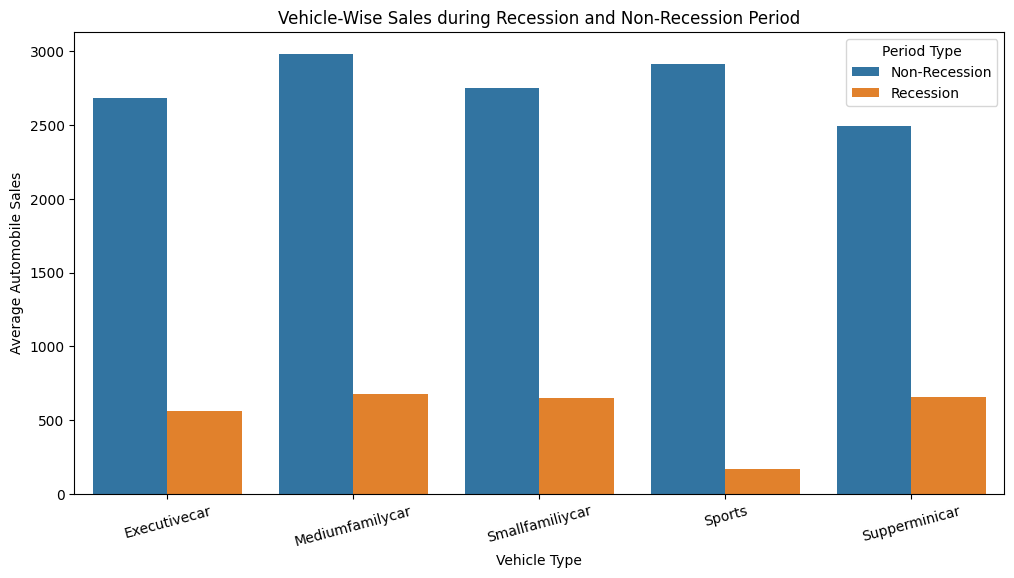

In [ ]:
# Group data by Recession and Vehicle_Type to calculate mean sales
grouped_df = df.groupby(['Recession', 'Vehicle_Type'], as_index=False)['Automobile_Sales'].mean()

# Optional: Map Recession values for clearer display
grouped_df['Recession_Status'] = grouped_df['Recession'].map({0: 'Non-Recession', 1: 'Recession'})

# Create the grouped bar chart using seaborn
plt.figure(figsize=(12, 6))
sns.barplot(x='Vehicle_Type', y='Automobile_Sales', hue='Recession_Status', data=grouped_df)

plt.xlabel('Vehicle Type')
plt.ylabel('Average Automobile Sales')
plt.title('Vehicle-Wise Sales during Recession and Non-Recession Period')
plt.xticks(rotation=15)
plt.legend(title='Period Type')

plt.show()

From this plot, we can understand that there is a drastic decline in the overall sales of the automobiles during recession.
However, the most affected type of vehicle is executivecar and sports

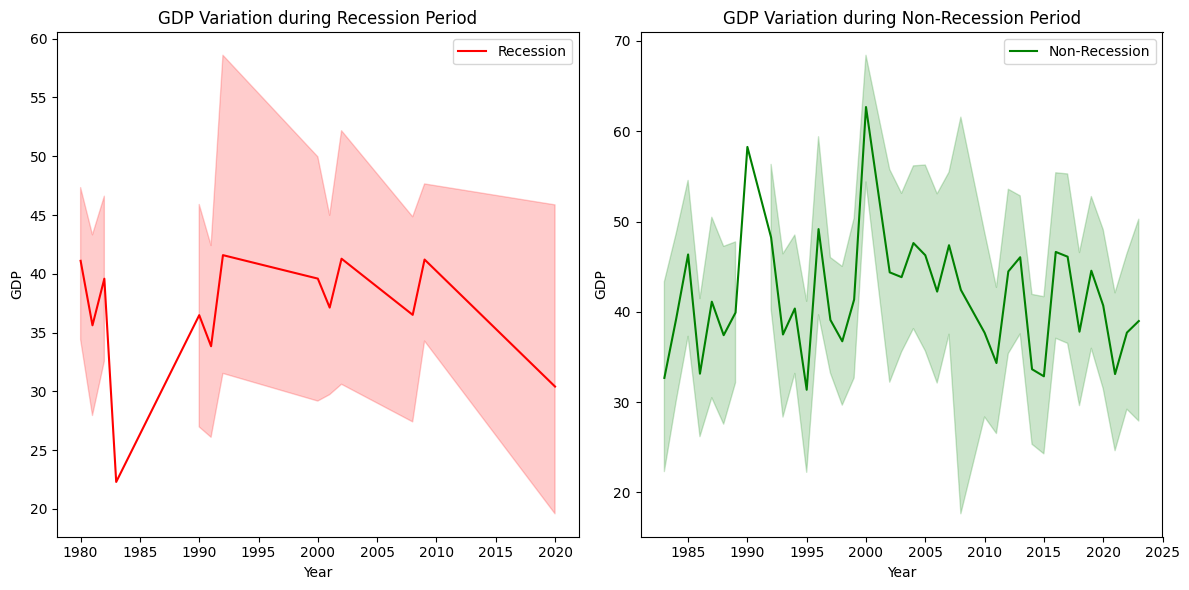

In [ ]:
# Create dataframes for recession and non-recession period
rec_data = df[df['Recession'] == 1]
non_rec_data = df[df['Recession'] == 0]

# Figure
fig = plt.figure(figsize=(12, 6))

# Create different axes for subplotting
ax0 = fig.add_subplot(1, 2, 1) # add subplot 1 (1 row, 2 columns, first plot)
ax1 = fig.add_subplot(1, 2, 2) # add subplot 2 (1 row, 2 columns, second plot)

# Subplot 1: Recession GDP trend
sns.lineplot(x='Year', y='GDP', data=rec_data, label='Recession', ax=ax0, color='red')
ax0.set_xlabel('Year')
ax0.set_ylabel('GDP')
ax0.set_title('GDP Variation during Recession Period')
ax0.legend()

# Subplot 2: Non-Recession GDP trend
sns.lineplot(x='Year', y='GDP', data=non_rec_data, label='Non-Recession', ax=ax1, color='green')
ax1.set_xlabel('Year')
ax1.set_ylabel('GDP')
ax1.set_title('GDP Variation during Non-Recession Period')
ax1.legend()

plt.tight_layout()
plt.show()

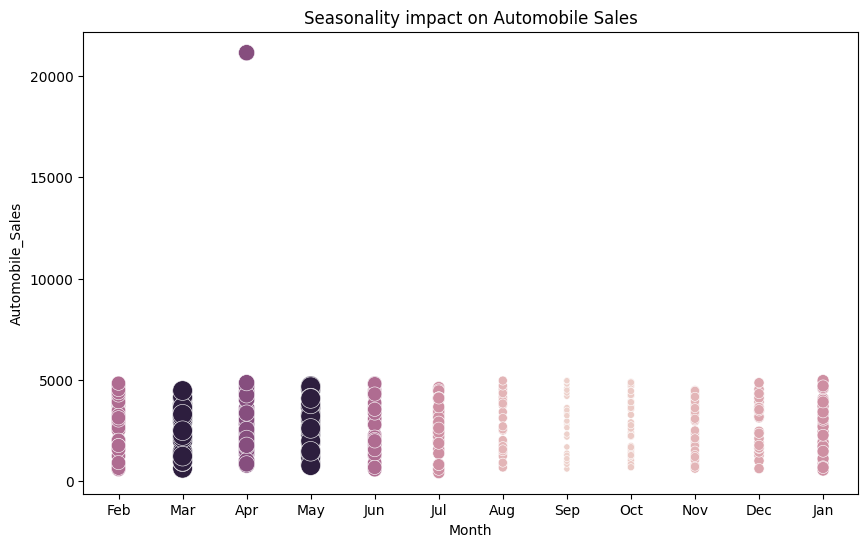

In [ ]:
non_rec_data = df[df['Recession'] == 0]

size = non_rec_data['Seasonality_Weight'] # for bubble effect

plt.figure(figsize=(10, 6))
sns.scatterplot(data=non_rec_data, x='Month', y='Automobile_Sales', size=size, hue='Seasonality_Weight', legend=False, sizes=(20, 200))

plt.xlabel('Month')
plt.ylabel('Automobile_Sales')
plt.title('Seasonality impact on Automobile Sales')

plt.show()

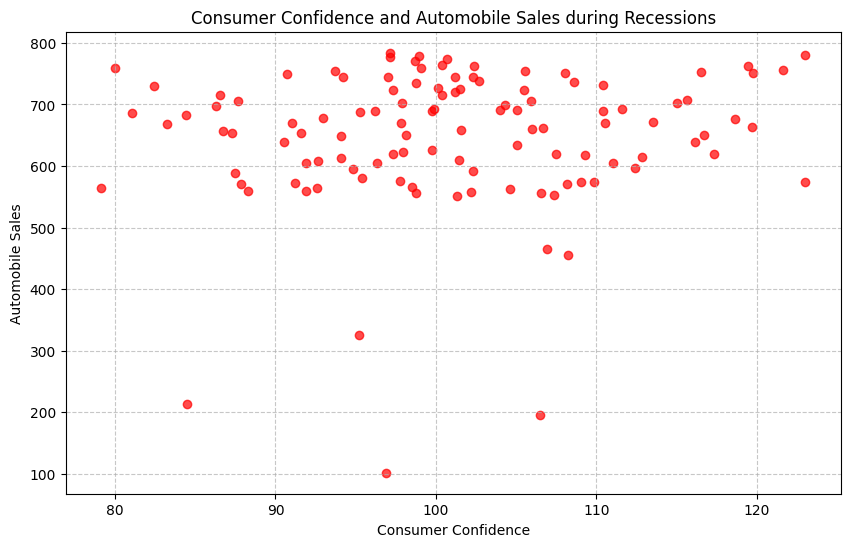

In [ ]:
# Filter dataset for recession periods where Recession is 1
rec_data = df[df['Recession'] == 1]

# Create figure and scatter plot using Matplotlib
plt.figure(figsize=(10, 6))
plt.scatter(rec_data['Consumer_Confidence'], rec_data['Automobile_Sales'], color='red', alpha=0.7)

plt.xlabel('Consumer Confidence')
plt.ylabel('Automobile Sales')
plt.title('Consumer Confidence and Automobile Sales during Recessions')
plt.grid(True, linestyle='--', alpha=0.7)

plt.show()

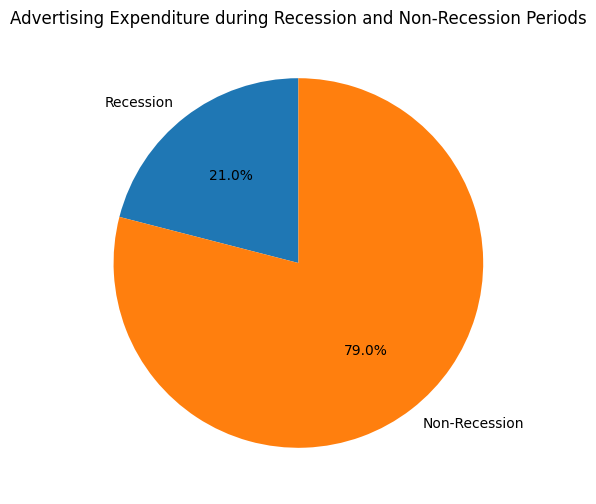

In [ ]:
# Filter the data
Rdata = df[df['Recession'] == 1]
NRdata = df[df['Recession'] == 0]

# Calculate the total advertising expenditure for both periods
RAtotal = Rdata['Advertising_Expenditure'].sum()
NRAtotal = NRdata['Advertising_Expenditure'].sum()

# Create a pie chart for the advertising expenditure
plt.figure(figsize=(8, 6))

labels = ['Recession', 'Non-Recession']
sizes = [RAtotal, NRAtotal]
plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=90)

plt.title('Advertising Expenditure during Recession and Non-Recession Periods')

plt.show()

Companies (like XYZAutomotives) tend to significantly cut down on their advertising expenditures during recession periods compared to non-recession periods. A much larger share of the total advertising budget is allocated during stable, non-recession economic climates when consumer spending confidence is higher.

In [ ]:
Here are the completed solution templates for both tasks, keeping everything strictly within **Matplotlib and Seaborn**:

### 1. Pie Chart: Advertisement Expenditure by Vehicle Type During Recession

```python
# Filter the data
Rdata = df[df['Recession'] == 1]

# Calculate the expenditure by vehicle type during recessions
VTexpenditure = Rdata.groupby('Vehicle_Type')['Advertising_Expenditure'].sum()

# Create a pie chart for the share of each vehicle type in total expenditure during recessions
plt.figure(figsize=(8, 6))

labels = VTexpenditure.index
sizes = VTexpenditure.values
plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=90)

plt.title('Share of Each Vehicle Type in Total Advertising Expenditure During Recessions')

plt.show()

```

---

### 2. TASK 1.9: Effect of Unemployment Rate on Vehicle Type and Sales during Recession

```python
# Filter out the data for recession period
rec_data = df[df['Recession'] == 1]

# Create the line plot using Seaborn
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=rec_data,
    x='Unemployment_Rate',
    y='Automobile_Sales',
    hue='Vehicle_Type',
    marker='o'
)

plt.xlabel('Unemployment Rate')
plt.ylabel('Automobile Sales')
plt.title('Effect of Unemployment Rate on Vehicle Type and Sales')
plt.legend(title='Vehicle Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

```

SyntaxError: invalid syntax (3188979284.py, line 1)

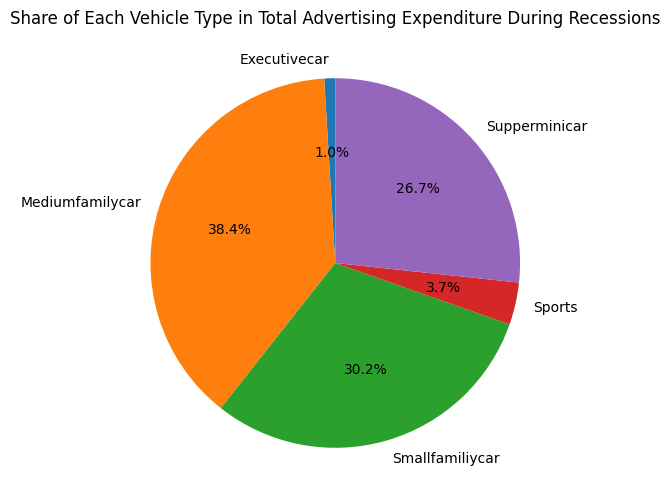

In [ ]:
# Filter the data
Rdata = df[df['Recession'] == 1]

# Calculate the expenditure by vehicle type during recessions
VTexpenditure = Rdata.groupby('Vehicle_Type')['Advertising_Expenditure'].sum()

# Create a pie chart for the share of each vehicle type in total expenditure during recessions
plt.figure(figsize=(8, 6))

labels = VTexpenditure.index
sizes = VTexpenditure.values
plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=90)

plt.title('Share of Each Vehicle Type in Total Advertising Expenditure During Recessions')

plt.show()

In [ ]:
# Filter out the data for recession period
rec_data = df[df['Recession'] == 1]

# Create the line plot using Seaborn
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=rec_data,
    x='Unemployment_Rate',
    y='Automobile_Sales',
    hue='Vehicle_Type',
    marker='o'
)

plt.xlabel('Unemployment Rate')
plt.ylabel('Automobile Sales')
plt.title('Effect of Unemployment Rate on Vehicle Type and Sales')
plt.legend(title='Vehicle Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

ValueError: Could not interpret value `Unemployment_Rate` for `x`. An entry with this name does not appear in `data`.

<Figure size 1200x600 with 0 Axes>

In [ ]:
# Filter out the data for recession period
rec_data = df[df['Recession'] == 1]

# Create the line plot using Seaborn (with space in column name)
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=rec_data,
    x='Unemployment Rate',
    y='Automobile_Sales',
    hue='Vehicle_Type',
    marker='o'
)

plt.xlabel('Unemployment Rate')
plt.ylabel('Automobile Sales')
plt.title('Effect of Unemployment Rate on Vehicle Type and Sales')
plt.legend(title='Vehicle Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

ValueError: Could not interpret value `Unemployment Rate` for `x`. An entry with this name does not appear in `data`.

<Figure size 1200x600 with 0 Axes>

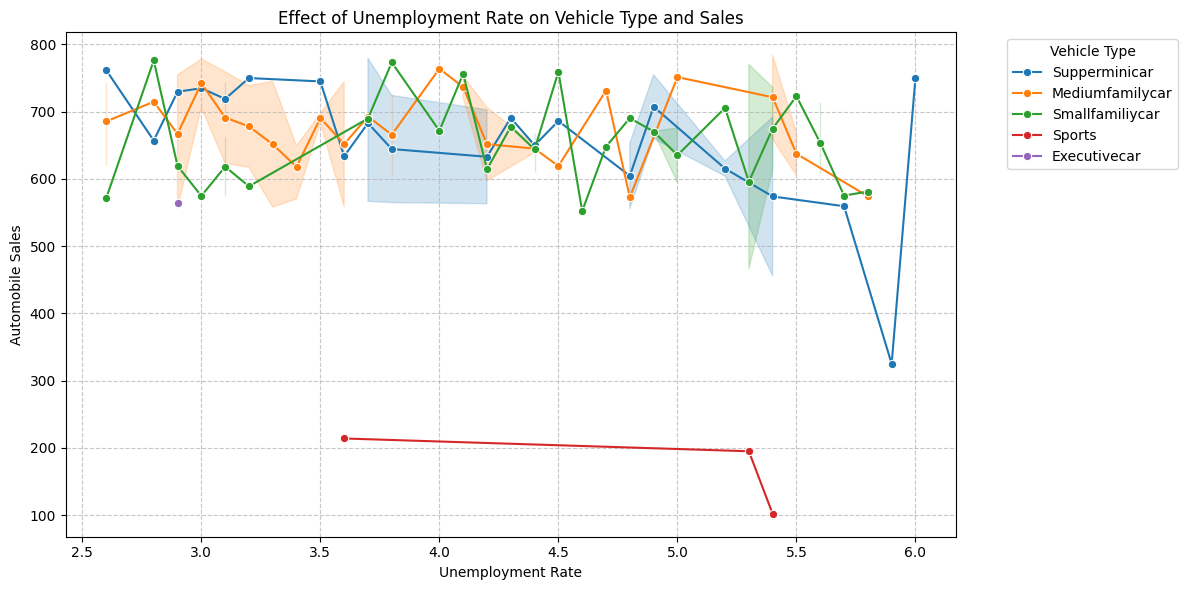

In [ ]:
# Filter out the data for recession period
rec_data = df[df['Recession'] == 1]

# Create the line plot using Seaborn with the correct column name 'unemployment_rate'
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=rec_data,
    x='unemployment_rate',
    y='Automobile_Sales',
    hue='Vehicle_Type',
    marker='o'
)

plt.xlabel('Unemployment Rate')
plt.ylabel('Automobile Sales')
plt.title('Effect of Unemployment Rate on Vehicle Type and Sales')
plt.legend(title='Vehicle Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

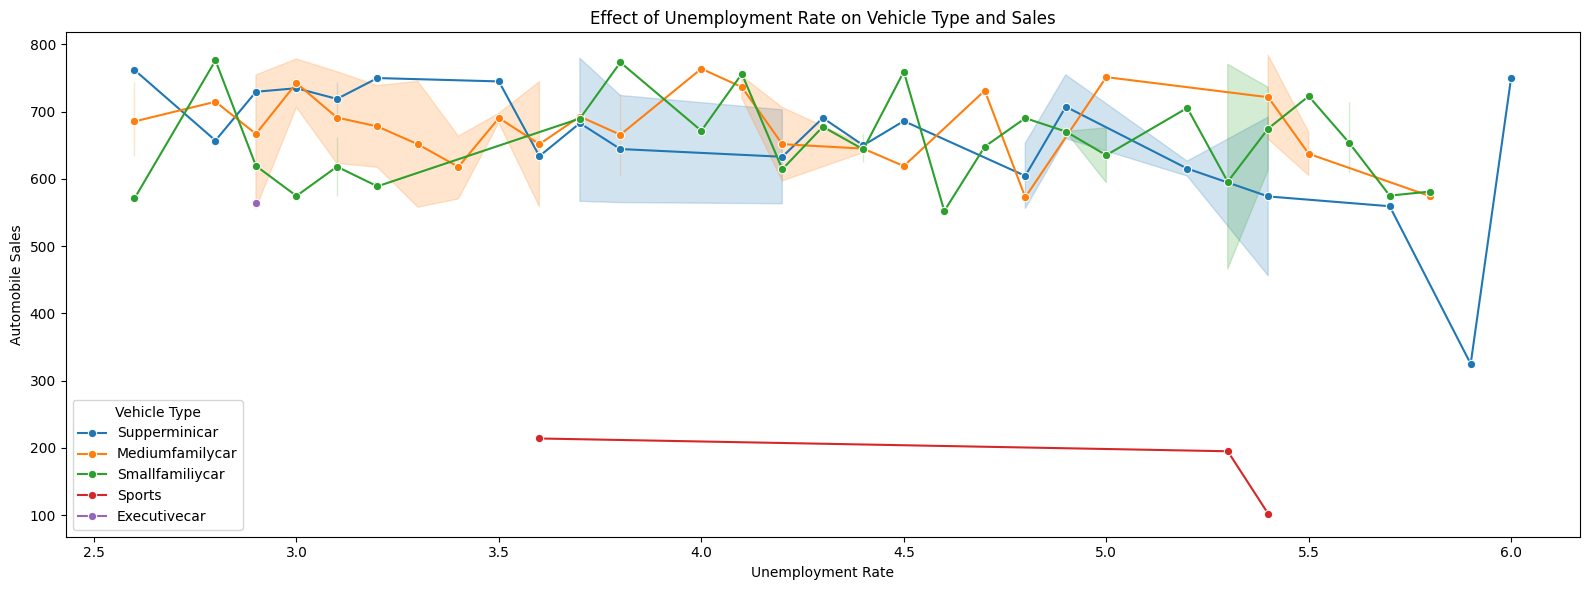

In [ ]:
# Assuming 'df' is your dataset
df_rec = df[df['Recession'] == 1]

# Set figure size
plt.figure(figsize=(16, 6))

# Create line plot showing effect of unemployment rate on automobile sales, by vehicle type
sns.lineplot(
    data=df_rec,
    x='unemployment_rate',
    y='Automobile_Sales',
    hue='Vehicle_Type',
    marker='o'
)

# Customize labels, legend, and title
plt.title('Effect of Unemployment Rate on Vehicle Type and Sales')
plt.xlabel('Unemployment Rate')
plt.ylabel('Automobile Sales')
plt.legend(title='Vehicle Type')

# Show plot
plt.tight_layout()
plt.show()

During recession periods, as the unemployment rate increases, the sales of more affordable, economical vehicle categories (such as superminicars and small family cars) tend to hold up better or show distinct buying patterns compared to luxury or medium-sized vehicles, as consumers shift toward budget-friendly options under financial uncertainty.

In [ ]:
import folium
import json

# Load the downloaded JSON file
with open("us-states.json") as f:
    state_geo = json.load(f)

# Initialize a Folium map centered over the United States
us_map = folium.Map(location=[37.0902, -95.7129], zoom_start=4)

# Add the GeoJSON boundaries to the map
folium.GeoJson(
    state_geo,
    name='States'
).add_to(us_map)

# Display the map
us_map

FileNotFoundError: [Errno 2] No such file or directory: 'us-states.json'

In [ ]:
from pyodide.http import pyfetch
import folium
import json
import os

async def download(url, filename):
    response = await pyfetch(url)
    if response.status == 200:
        with open(filename, "wb") as f:
            f.write(await response.bytes())

path = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/Data%20Files/us-states.json'
filename = "us-states.json"

# Download the file first and wait for it
await download(path, filename)

# Verify the file exists before opening
if os.path.exists(filename):
    print("File downloaded successfully!")

    # Load the downloaded JSON file
    with open(filename) as f:
        state_geo = json.load(f)

    # Initialize a Folium map centered over the United States
    us_map = folium.Map(location=[37.0902, -95.7129], zoom_start=4)

    # Add the GeoJSON boundaries to the map
    folium.GeoJson(
        state_geo,
        name='States'
    ).add_to(us_map)

    # Display the map
    display(us_map)
else:
    print("Download failed or file path is incorrect.")

ModuleNotFoundError: No module named 'pyodide'